<a href="https://colab.research.google.com/github/ks148678-beep/Data-Warehousing-and-Data-Mining/blob/main/correlation_and_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('automobileEDA.csv')
print("Loaded:", df.shape)
df.head()

Loaded: (201, 29)


,symboling,normalized-losses,make,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,...,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price,city-L/100km,horsepower-binned,diesel,gas
0,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,13495.0,11.190476,Medium,0,1
1,3,122,alfa-romero,std,two,convertible,rwd,front,88.6,0.811148,...,9.0,111.0,5000.0,21,27,16500.0,11.190476,Medium,0,1
2,1,122,alfa-romero,std,two,hatchback,rwd,front,94.5,0.822681,...,9.0,154.0,5000.0,19,26,16500.0,12.368421,Medium,0,1
3,2,164,audi,std,four,sedan,fwd,front,99.8,0.848630,...,10.0,102.0,5500.0,24,30,13950.0,9.791667,Medium,0,1
4,2,164,audi,std,four,sedan,4wd,front,99.4,0.848630,...,8.0,115.0,5500.0,18,22,17450.0,13.055556,Medium,0,1


/tmp/ipykernel_738/4412625.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['stroke'].fillna(df['stroke'].median(), inplace=True)


price                1.000000
engine-size          0.872335
curb-weight          0.834415
horsepower           0.809575
city-L/100km         0.789898
width                0.751265
length               0.690628
wheel-base           0.584642
bore                 0.543155
height               0.135486
normalized-losses    0.133999
diesel               0.110326
stroke               0.082209
compression-ratio    0.071107
symboling           -0.082391
peak-rpm            -0.101616
gas                 -0.110326
city-mpg            -0.686571
highway-mpg         -0.704692
Name: price, dtype: float64


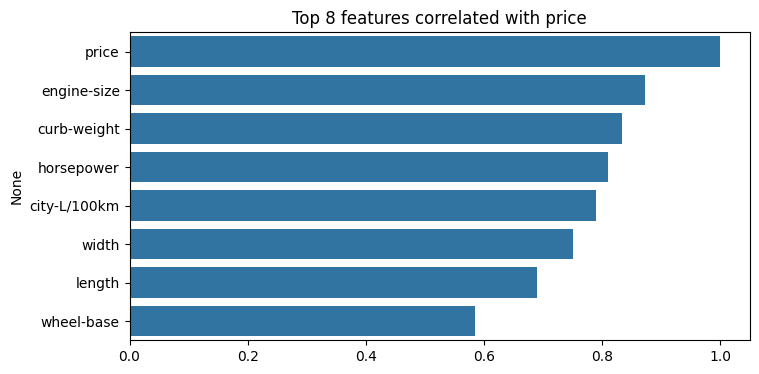

In [12]:
# Fix the 4 missing stroke values (as per your research doc)
df['stroke'].fillna(df['stroke'].median(), inplace=True)

# Which features correlate most with price?
corr_price = df.corr(numeric_only=True)['price'].sort_values(ascending=False)
print(corr_price)

# Draw it
plt.figure(figsize=(8,4))
sns.barplot(x=corr_price.values[:8], y=corr_price.index[:8])
plt.title("Top 8 features correlated with price")
plt.show()

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Prepare: Use only numeric columns, fill missing
df_clean = df.copy()
df_clean['horsepower-binned'] = df_clean['horsepower-binned'].fillna('Medium')

# Simple numeric features for quick model
features = ['engine-size','curb-weight','horsepower','width','city-L/100km']
X = df_clean[features]
y = df_clean['price']

# 80% train, 20% test (as per your doc - stratified)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 1. Simple Regression (only engine-size)
lr_simple = LinearRegression()
lr_simple.fit(X_train[['engine-size']], y_train)
pred_simple = lr_simple.predict(X_test[['engine-size']])

# 2. Multiple Regression
lr_multi = LinearRegression()
lr_multi.fit(X_train, y_train)
pred_multi = lr_multi.predict(X_test)

# 3. Ridge (fixes multicollinearity)
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
pred_ridge = ridge.predict(X_test)

# 4. Random Forest (Machine Learning)
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

def eval_model(name, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    print(f"{name:20s} | R2={r2:.3f} | RMSE=${rmse:.0f} | MAE=${mae:.0f}")

print("=== MODEL COMPARISON ON TEST SET (40 cars) ===")
eval_model("Simple Regression", y_test, pred_simple)
eval_model("Multiple Regression", y_test, pred_multi)
eval_model("Ridge Regression", y_test, pred_ridge)
eval_model("Random Forest", y_test, pred_rf)

# Which features matter most? (for Objective 5)
importance = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
print("\n=== RANDOM FOREST IMPORTANCE ===")
print(importance)

=== MODEL COMPARISON ON TEST SET (40 cars) ===
Simple Regression    | R2=0.725 | RMSE=$5805 | MAE=$4176
Multiple Regression  | R2=0.754 | RMSE=$5483 | MAE=$3850
Ridge Regression     | R2=0.756 | RMSE=$5460 | MAE=$3870
Random Forest        | R2=0.939 | RMSE=$2741 | MAE=$1781

=== RANDOM FOREST IMPORTANCE ===
curb-weight     0.478462
engine-size     0.330577
horsepower      0.082509
width           0.056541
city-L/100km    0.051911
dtype: float64


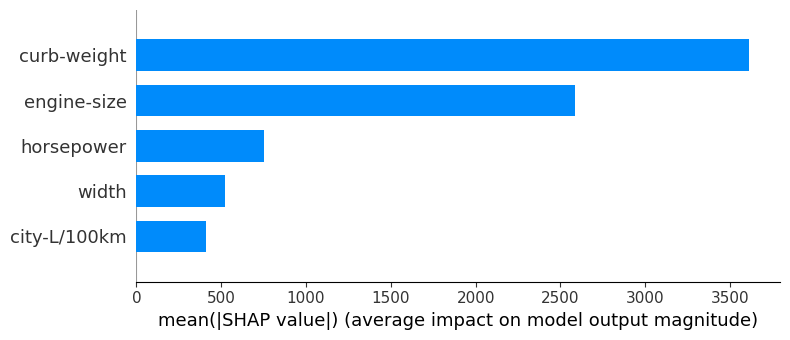

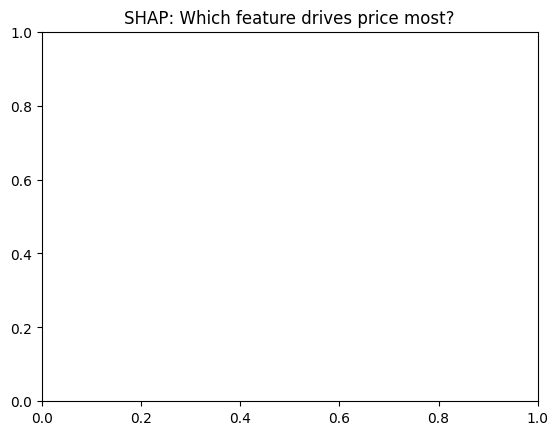

In [14]:
import shap
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test, plot_type="bar")
plt.title("SHAP: Which feature drives price most?")
plt.show()